<a href="https://colab.research.google.com/github/yuliatasiyah/Yulia-Tasiyah_B1C024027/blob/main/Kelompok_9_Notebook_Pima_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Akhir: Klasifikasi Status Diabetes pada Perempuan Suku Pima

**Kelompok:** [9]
**Anggota:** [Nama Widia], [Nama Yulia], [Nama Yoel]
**Mata kuliah:** [isi nama mata kuliah]

## Cara memakai notebook ini (baca dulu)

1. Di Google Colab, klik **Runtime → Run all** (Jalankan semua). Tunggu sampai selesai (sekitar 1-3 menit).
2. Kalau muncul error, jangan panik. Baca baris paling bawah pesan error-nya, lalu tanya Claude dengan menyalin pesan itu.
3. Notebook dibagi menjadi tiga bagian. Setiap bagian punya pemilik, tetapi **semua orang tetap harus paham seluruh isinya**:
   - **Bagian A:** memahami data, grafik eksplorasi (EDA), dan menyiapkan data
   - **Bagian B:** melatih dan membandingkan model, menyetel model, lalu evaluasi akhir
   - **Bagian C:** menafsirkan fitur secara biologis, serta PCA dan K-Means
4. Sel yang berjudul **"Interpretasi (isi sendiri)"** sengaja dikosongkan. Isi setelah melihat hasilnya, dengan bahasa kalian sendiri.

## Tujuan project

Memakai data klinis 768 perempuan suku Pima untuk memprediksi apakah seseorang menderita diabetes, lalu menjelaskan hasilnya dari sudut pandang biologi.

## Kamus kolom data

| Kolom | Arti |
|---|---|
| Pregnancies | Jumlah kehamilan |
| Glucose | Kadar glukosa plasma 2 jam setelah tes toleransi glukosa oral (mg/dL) |
| BloodPressure | Tekanan darah diastolik (mmHg) |
| SkinThickness | Ketebalan lipatan kulit trisep (mm) |
| Insulin | Kadar insulin serum 2 jam (µU/mL) |
| BMI | Indeks massa tubuh (Body Mass Index), kg/m² |
| DiabetesPedigreeFunction | Skor kecenderungan genetik dari riwayat diabetes keluarga |
| Age | Usia (tahun) |
| **Outcome** | **Target: 1 = diabetes, 0 = tidak diabetes** |

## 0. Persiapan: memanggil alat (library) dan memuat data

**Apa yang dilakukan sel di bawah ini?** Memanggil alat-alat Python yang dibutuhkan, lalu mengunduh data Pima dari OpenML. Kalau pengunduhan gagal, notebook akan meminta kalian mengunggah file CSV dari Kaggle.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, silhouette_score, adjusted_rand_score)

RANDOM_STATE = 42   # angka tetap supaya hasil selalu sama setiap dijalankan
sns.set_theme(style="whitegrid")

In [ ]:
# Memuat data Pima Indians Diabetes dari OpenML
NAMA_BARU = {"preg": "Pregnancies", "plas": "Glucose", "pres": "BloodPressure",
             "skin": "SkinThickness", "insu": "Insulin", "mass": "BMI",
             "pedi": "DiabetesPedigreeFunction", "age": "Age", "class": "Outcome"}

try:
    raw = fetch_openml("diabetes", version=1, as_frame=True).frame
    raw = raw.rename(columns=NAMA_BARU)
    raw["Outcome"] = (raw["Outcome"] == "tested_positive").astype(int)   # positif diabetes -> 1
    print("Data berhasil dimuat dari OpenML.")
except Exception as e:
    print("Gagal memuat dari OpenML:", e)
    print("Unggah file diabetes.csv dari Kaggle (kolom: Pregnancies, Glucose, ..., Outcome).")
    from google.colab import files
    terunggah = files.upload()
    raw = pd.read_csv(list(terunggah.keys())[0])

print("Ukuran data (baris, kolom):", raw.shape)
raw.head()

Data berhasil dimuat dari OpenML.
Ukuran data (baris, kolom): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


---
# BAGIAN A — Memahami dan menyiapkan data

## 1. Data understanding (mengenali isi data)

**Apa tujuannya?** Sebelum membuat model, kita harus tahu isi datanya: berapa baris, tipe kolom, ada data kosong atau tidak, dan berapa pasien diabetes dibanding yang tidak.

In [ ]:
FITUR = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
         "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
KOLOM_NOL = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df = raw.copy()
df.info()

NameError: name 'raw' is not defined

In [ ]:
# Ringkasan statistik tiap kolom (rata-rata, minimum, maksimum, dst.)
df.describe().T

NameError: name 'df' is not defined

In [ ]:
# Proporsi kelas: berapa pasien diabetes (1) dan tidak diabetes (0)?
jumlah = df["Outcome"].value_counts().sort_index()
persen = (df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(1)
pd.DataFrame({"Jumlah": jumlah, "Persen (%)": persen}, index=["0 = tidak diabetes", "1 = diabetes"])

,Jumlah,Persen (%)
0 = tidak diabetes,NaN,NaN
1 = diabetes,NaN,NaN


In [ ]:
# Memeriksa nilai 0 yang tidak masuk akal secara biologis
# Glukosa, tekanan darah, ketebalan kulit, insulin, dan BMI tidak mungkin bernilai 0 pada manusia hidup.
nol = (df[KOLOM_NOL] == 0).sum()
tabel_nol = pd.DataFrame({"Jumlah nilai 0": nol, "Persen (%)": (nol / len(df) * 100).round(1)})
print(tabel_nol)
print("\nPregnancies bernilai 0 (sah, artinya belum pernah hamil):", (df["Pregnancies"] == 0).sum())

               Jumlah nilai 0  Persen (%)
Glucose                     5         0.7
BloodPressure              35         4.6
SkinThickness             227        29.6
Insulin                   374        48.7
BMI                        11         1.4

Pregnancies bernilai 0 (sah, artinya belum pernah hamil): 111


### Interpretasi
Dataset yang digunakan terdiri atas 768 data dengan 9 kolom, yaitu 8 variabel prediktor dan 1 variabel target (Outcome). Pemeriksaan data menunjukkan adanya nilai 0 pada beberapa variabel klinis, dengan jumlah terbanyak pada Insulin sebanyak 374 data (48,7%), diikuti SkinThickness sebanyak 227 data (29,6%). Nilai 0 pada variabel tersebut tidak menggambarkan kondisi biologis yang normal, sehingga kemungkinan merupakan data yang tidak tercatat atau pengukuran yang hilang. Hal ini dapat memengaruhi hasil analisis sehingga perlu ditangani pada tahap prapemrosesan data. Sementara itu, nilai 0 pada Pregnancies masih dapat dianggap valid karena menunjukkan individu yang belum pernah mengalami kehamilan. Proporsi kelas Outcome juga perlu diperhatikan untuk mengetahui keseimbangan jumlah individu diabetes dan non-diabetes, karena ketidakseimbangan kelas dapat memengaruhi evaluasi model. Oleh karena itu, model tidak hanya dinilai berdasarkan akurasi, tetapi juga menggunakan precision, recall, F1-score, dan ROC-AUC.

## 2. EDA (Exploratory Data Analysis / eksplorasi data lewat grafik)

**Apa tujuannya?** Melihat bentuk data lewat tiga grafik: sebaran tiap fitur, perbandingan antara pasien diabetes dan bukan, serta hubungan antar fitur. Grafik ini akan dipakai di BAB IV.

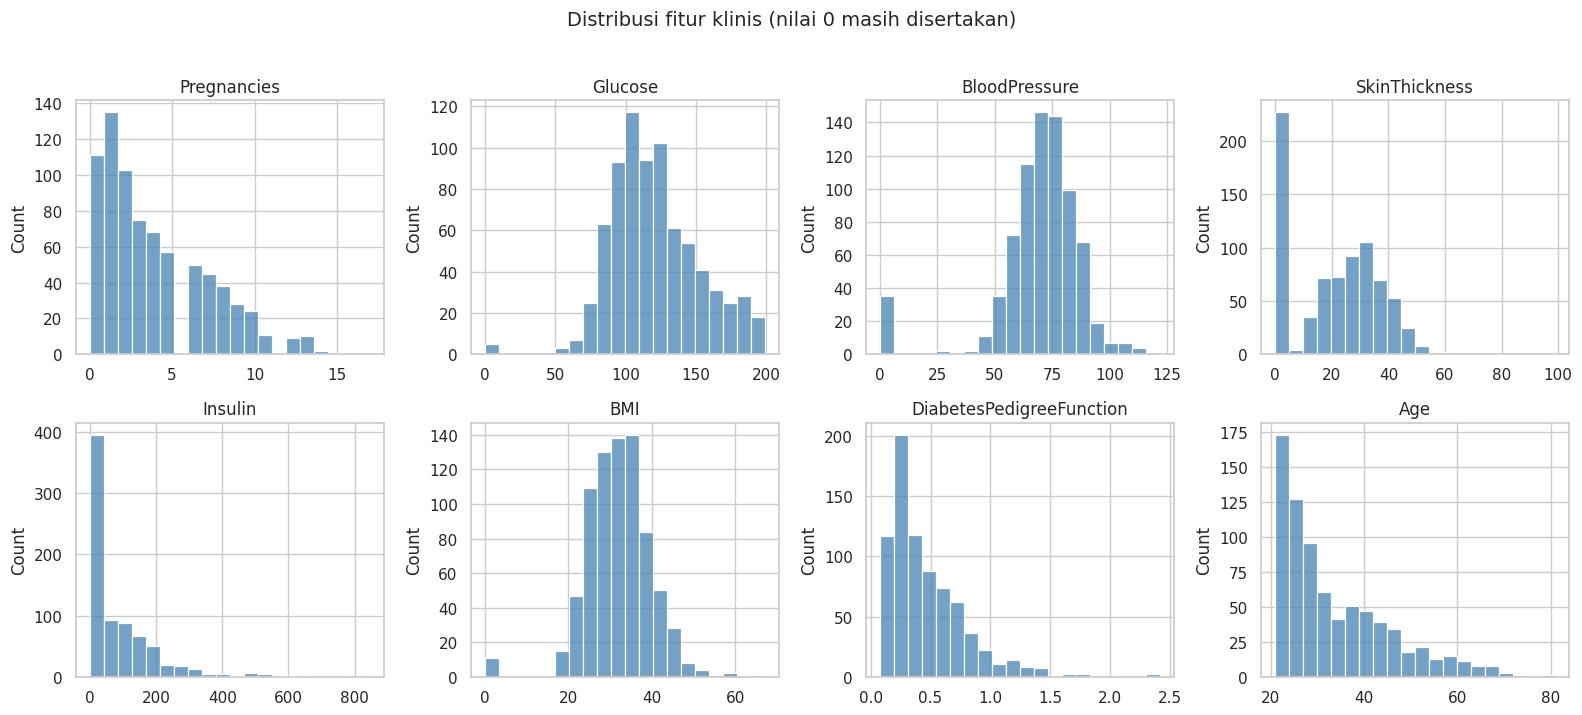

In [ ]:
# Grafik 1: histogram (sebaran tiap fitur)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), FITUR):
    sns.histplot(df[f], bins=20, ax=ax, color="steelblue")
    ax.set_title(f)
    ax.set_xlabel("")
plt.suptitle("Distribusi fitur klinis (nilai 0 masih disertakan)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

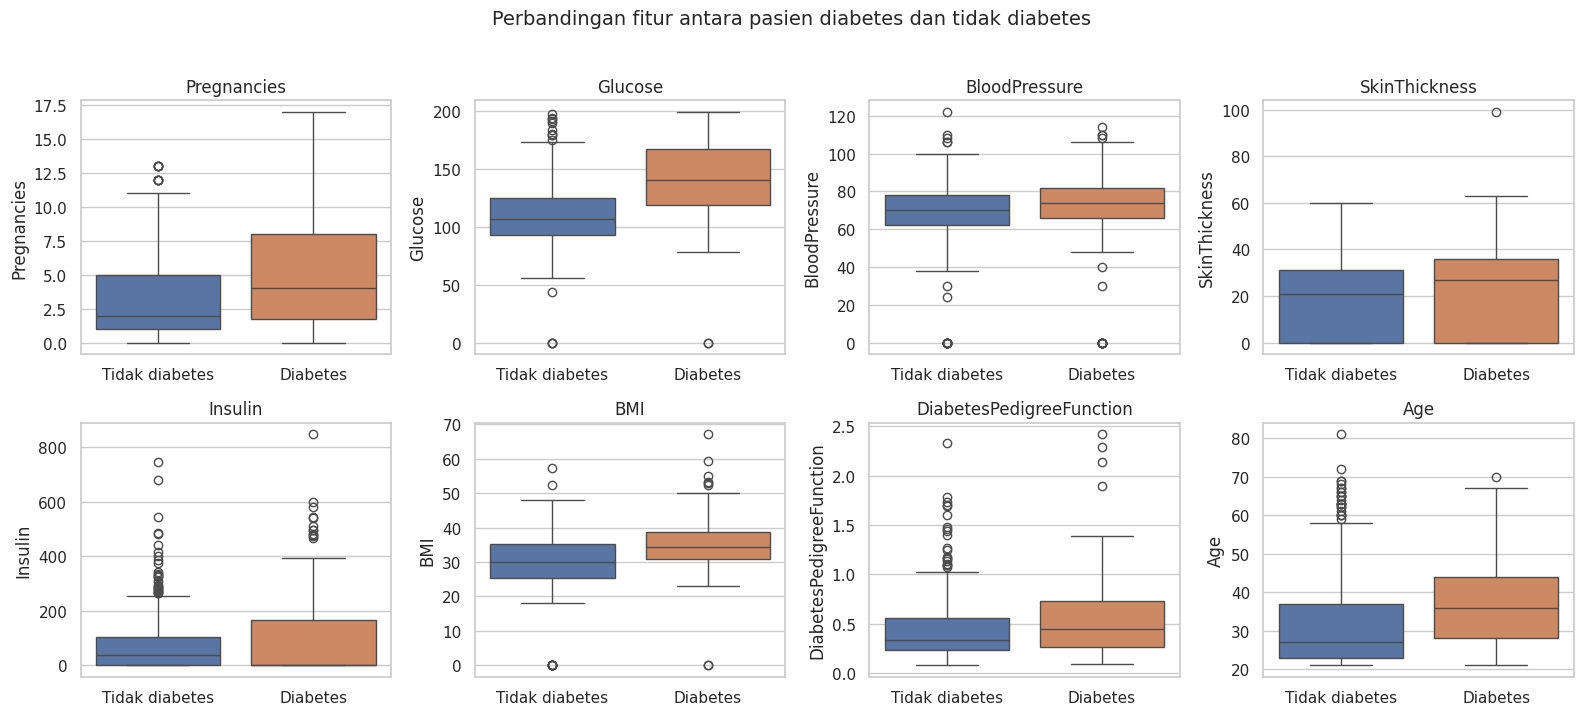

In [ ]:
# Grafik 2: boxplot per kelas (apakah nilai fitur berbeda antara diabetes dan tidak?)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), FITUR):
    sns.boxplot(x="Outcome", y=f, data=df, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_xticklabels(["Tidak diabetes", "Diabetes"])
    ax.set_xlabel("")
    ax.set_title(f)
plt.suptitle("Perbandingan fitur antara pasien diabetes dan tidak diabetes", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

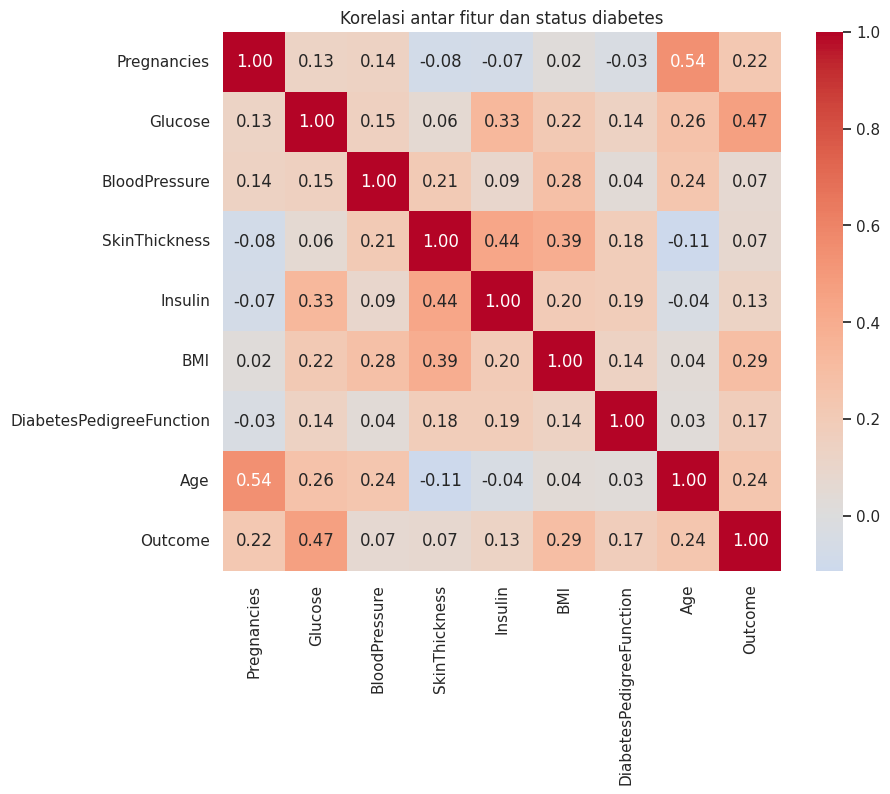

In [ ]:
# Grafik 3: heatmap korelasi (seberapa kuat hubungan antar kolom, termasuk dengan Outcome)
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur dan status diabetes")
plt.show()

### Interpretasi
Berdasarkan histogram, beberapa fitur memiliki sebaran miring ke kanan dan nilai ekstrem, terutama Pregnancies, Insulin, DiabetesPedigreeFunction, dan Age. Insulin memiliki sebaran paling mencolok karena banyak nilai 0 dan terdapat beberapa nilai yang sangat tinggi. Pada boxplot, kelompok diabetes cenderung memiliki nilai Glucose, BMI, Age, dan Pregnancies lebih tinggi dibandingkan kelompok tidak diabetes. Glucose menunjukkan perbedaan yang paling jelas antara kedua kelompok. Berdasarkan heatmap, Glucose memiliki korelasi paling tinggi dengan Outcome sebesar 0,47, diikuti BMI (0,29) dan Age (0,24). Sementara itu, korelasi antarfitur paling tinggi terdapat pada Pregnancies dan Age sebesar 0,54, diikuti SkinThickness dan Insulin sebesar 0,44. Hasil ini menunjukkan bahwa Glucose merupakan fitur yang paling berkaitan dengan status diabetes pada eksplorasi awal, sedangkan beberapa fitur lainnya juga menunjukkan keterkaitan, tetapi dengan korelasi yang lebih rendah.

## 3. Preprocessing (menyiapkan data)

**Apa yang dilakukan?**
1. Nilai 0 yang tidak masuk akal diubah menjadi **kosong (NaN)**.
2. Data dibagi: **80% untuk belajar (latih)** dan **20% untuk ujian akhir (uji)**. Pembagian memakai `stratify` supaya persentase pasien diabetes sama di kedua bagian.
3. Disiapkan **Pipeline**: rangkaian langkah "isi data kosong dengan median, lalu samakan skala, lalu model". Pipeline memastikan angka median dan skala **hanya dihitung dari data latih**. Kalau dihitung dari seluruh data, data uji ikut "mengintip" dan hasilnya tampak lebih bagus dari kenyataan. Itulah yang disebut *data leakage* (kebocoran data), dan itu yang dilarang di tugas.

In [ ]:
# Langkah 1: nilai 0 yang tidak wajar -> NaN
data = df.copy()
data[KOLOM_NOL] = data[KOLOM_NOL].replace(0, np.nan)
print("Jumlah data kosong (NaN) per kolom setelah pembersihan:")
print(data[FITUR].isna().sum())

Jumlah data kosong (NaN) per kolom setelah pembersihan:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [ ]:
# Langkah 2: memisahkan fitur (X) dan target (y), lalu membagi data latih dan data uji
X = data[FITUR]
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Persen diabetes di data latih:", round(y_train.mean() * 100, 1), "%")
print("Persen diabetes di data uji  :", round(y_test.mean() * 100, 1), "%")

Data latih: (614, 8) | Data uji: (154, 8)
Persen diabetes di data latih: 34.9 %
Persen diabetes di data uji  : 35.1 %


In [ ]:
# Langkah 3: pembuat Pipeline (imputasi median -> penskalaan -> model)
def buat_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # isi data kosong dengan median
        ("scaler", StandardScaler()),                    # samakan skala semua fitur
        ("model", model),
    ])

### Interpretasi
Nilai 0 pada Glucose, BloodPressure, SkinThickness, Insulin, dan BMI diubah menjadi NaN karena tidak menggambarkan pengukuran biologis yang normal dan kemungkinan merupakan data yang tidak tercatat, sedangkan nilai 0 pada Pregnancies tetap dipertahankan karena menunjukkan individu yang belum pernah hamil. Data kosong diisi menggunakan median karena lebih tahan terhadap pengaruh nilai ekstrem dibandingkan rata-rata, sehingga lebih sesuai dengan data yang memiliki sebaran miring dan outlier. Penskalaan dilakukan agar seluruh fitur memiliki skala yang sebanding, karena Logistic Regression dan SVM dapat dipengaruhi oleh perbedaan skala antarvariabel. Data kemudian dibagi menjadi 80% data latih dan 20% data uji dengan stratify agar proporsi diabetes pada kedua kelompok tetap serupa. Pipeline digunakan untuk menggabungkan imputasi, penskalaan, dan pemodelan, sehingga nilai median serta parameter scaling dipelajari hanya dari data latih dan diterapkan pada data uji. Dengan demikian, data leakage dapat dihindari dan evaluasi model menjadi lebih objektif.

---
# BAGIAN B — Melatih, menyetel, dan menguji model

## 4. Membandingkan model dengan validasi silang

**Apa yang dilakukan?** Empat model dicoba:
- **Baseline:** model "malas" yang selalu menebak kelas terbanyak (tidak diabetes). Ini pembanding. Model lain baru berarti kalau jelas lebih baik daripada ini.
- **Logistic Regression**, **Random Forest**, dan **SVM** (Support Vector Machine).

Perbandingan memakai **validasi silang 5 lipatan**: data latih dibagi 5 bagian, model belajar dari 4 bagian lalu diuji di 1 bagian sisanya, diulang 5 kali bergantian. Hasilnya dilaporkan sebagai **rata-rata ± simpangan baku (std)**. Cara ini lebih adil daripada satu kali uji.

**Metrik yang dilihat:** akurasi, precision, recall, F1, dan ROC-AUC (Receiver Operating Characteristic - Area Under the Curve). Karena kelasnya tidak seimbang, **F1 dan ROC-AUC** lebih penting daripada akurasi.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline": buat_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": buat_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Random Forest": buat_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    "SVM": buat_pipeline(SVC(random_state=RANDOM_STATE)),
}

scoring = {
    "Akurasi": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",
}

baris, rata2 = [], {}
for nama, model in models.items():
    hasil = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rata2[nama] = {k: hasil[f"test_{k}"].mean() for k in scoring}
    baris.append({"Model": nama, **{k: f"{hasil[f'test_{k}'].mean():.3f} ± {hasil[f'test_{k}'].std():.3f}" for k in scoring}})

tabel_cv = pd.DataFrame(baris).set_index("Model")
tabel_cv

,Akurasi,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline,0.651 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.788 ± 0.019,0.764 ± 0.060,0.575 ± 0.023,0.655 ± 0.024,0.843 ± 0.019
Random Forest,0.774 ± 0.027,0.710 ± 0.068,0.608 ± 0.016,0.653 ± 0.025,0.820 ± 0.022
SVM,0.780 ± 0.014,0.742 ± 0.064,0.584 ± 0.057,0.648 ± 0.019,0.833 ± 0.023


### Interpretasi
Berdasarkan hasil validasi silang 5 lipatan, Logistic Regression memiliki performa terbaik dengan nilai F1 sebesar 0,655 dan ROC-AUC sebesar 0,843, diikuti Random Forest (F1 0,653; ROC-AUC 0,820) dan SVM (F1 0,648; ROC-AUC 0,833). Ketiga model memiliki performa yang relatif mirip karena selisih nilai F1 lebih kecil dibandingkan simpangan bakunya, sehingga keunggulan Logistic Regression belum terlihat jelas dibandingkan model lainnya. Meskipun demikian, ketiga model mampu memberikan hasil yang lebih baik daripada baseline, yang memiliki F1 sebesar 0 dan ROC-AUC 0,500. Akurasi baseline sebesar 65,1% diperoleh karena model selalu memprediksi kelas mayoritas, yaitu tidak diabetes, tanpa berhasil mendeteksi satu pun individu diabetes. Oleh karena itu, F1 dan ROC-AUC lebih informatif untuk membandingkan kemampuan model dalam mengenali diabetes pada dataset yang memiliki proporsi kelas tidak seimbang.

## 5. Menyetel model terbaik (hyperparameter tuning)

**Apa yang dilakukan?** Model terbaik dari tahap 4 (berdasarkan ROC-AUC) dicoba dengan beberapa kombinasi pengaturan memakai `GridSearchCV`, lalu dipilih kombinasi terbaik. Penyetelan hanya memakai **data latih**.

In [ ]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__n_estimators": [100, 300],
                      "model__max_depth": [None, 5, 10],
                      "model__min_samples_leaf": [1, 3, 5]},
    "SVM": {"model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"],
            "model__gamma": ["scale", "auto"]},
}

# model terbaik = ROC-AUC tertinggi pada validasi silang, tidak termasuk baseline
nama_terbaik = max((n for n in rata2 if n != "Baseline"), key=lambda n: rata2[n]["ROC-AUC"])
print("Model yang disetel:", nama_terbaik)

gs = GridSearchCV(models[nama_terbaik], param_grids[nama_terbaik], cv=cv, scoring="roc_auc", n_jobs=-1)
gs.fit(X_train, y_train)

print("Parameter terbaik:", gs.best_params_)
print("ROC-AUC validasi silang terbaik:", round(gs.best_score_, 3))
print("ROC-AUC validasi silang sebelum disetel:", round(rata2[nama_terbaik]["ROC-AUC"], 3))

Model yang disetel: Logistic Regression
Parameter terbaik: {'model__C': 0.1}
ROC-AUC validasi silang terbaik: 0.844
ROC-AUC validasi silang sebelum disetel: 0.843


## 6. Evaluasi akhir pada data uji (hanya SEKALI)

**Aturannya:** data uji adalah "ujian akhir". Tidak boleh dipakai untuk memilih model atau pengaturan, dan **sel di bawah ini jangan dijalankan berulang-ulang sambil mengubah model**, karena itu sama saja dengan mengintip soal ujian.

In [ ]:
model_akhir = gs.best_estimator_
y_pred = model_akhir.predict(X_test)

# skor kepercayaan model (untuk ROC): probabilitas bila ada, jika tidak pakai decision_function
if hasattr(model_akhir, "predict_proba"):
    skor = model_akhir.predict_proba(X_test)[:, 1]
else:
    skor = model_akhir.decision_function(X_test)

print("Laporan klasifikasi pada data uji:\n")
print(classification_report(y_test, y_pred, target_names=["Tidak diabetes", "Diabetes"], digits=3))
print("ROC-AUC data uji:", round(roc_auc_score(y_test, skor), 3))

Laporan klasifikasi pada data uji:

                precision    recall  f1-score   support

Tidak diabetes      0.741     0.800     0.769       100
      Diabetes      0.565     0.481     0.520        54

      accuracy                          0.688       154
     macro avg      0.653     0.641     0.645       154
  weighted avg      0.679     0.688     0.682       154

ROC-AUC data uji: 0.81


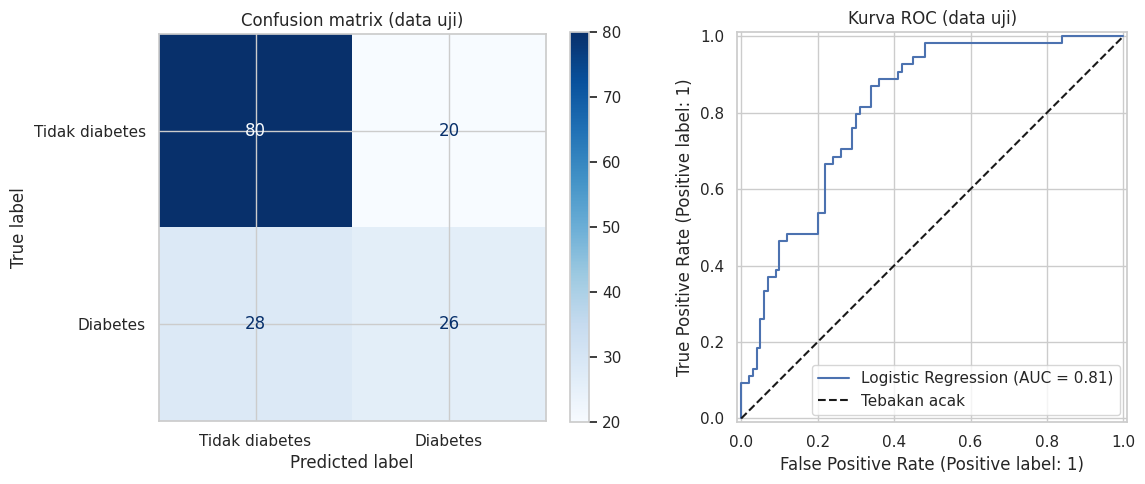

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Tidak diabetes", "Diabetes"], cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (data uji)")

RocCurveDisplay.from_predictions(y_test, skor, ax=axes[1], name=nama_terbaik)
axes[1].plot([0, 1], [0, 1], "k--", label="Tebakan acak")
axes[1].set_title("Kurva ROC (data uji)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretasi
Pada data uji, model Logistic Regression berhasil mendeteksi 26 dari 54 individu yang benar-benar diabetes, sedangkan 28 individu lainnya terlewat (False Negative). Hal ini menunjukkan recall sebesar 0,481, sehingga model masih belum mampu mendeteksi sebagian besar kasus diabetes secara optimal. False Negative menjadi perhatian dalam skrining karena individu yang sebenarnya diabetes dapat tidak menyadari kondisinya dan berpotensi terlambat mendapatkan pemeriksaan atau penanganan. Hasil evaluasi data uji menunjukkan penurunan performa dibandingkan validasi silang, terutama pada accuracy, precision, recall, dan F1, sedangkan ROC-AUC menurun dari 0,843 menjadi 0,810 dan masih relatif dekat. ROC-AUC sebesar 0,810 menunjukkan model memiliki kemampuan diskriminasi yang cukup baik dalam membedakan individu diabetes dan tidak diabetes, meskipun kemampuan deteksi pada threshold yang digunakan masih perlu ditingkatkan. Oleh karena itu, model ini berpotensi digunakan sebagai pendukung skrining awal, tetapi belum cukup baik untuk digunakan sebagai alat diagnosis.

---
# BAGIAN C — Tafsiran biologis dan pengelompokan tanpa label

## 7. Fitur mana yang paling berpengaruh?

**Apa yang dilakukan?** Dua cara menilai pengaruh fitur:
- **Koefisien Logistic Regression:** angka positif berarti makin besar nilai fitur, makin besar peluang diabetes. Fitur sudah diskalakan sehingga angkanya bisa dibandingkan.
- **Feature importance Random Forest:** seberapa sering fitur itu dipakai pohon untuk memisahkan kelas (makin besar makin penting, tanpa arah).

Keduanya dilatih ulang pada data latih supaya kedua cara bisa dibandingkan.

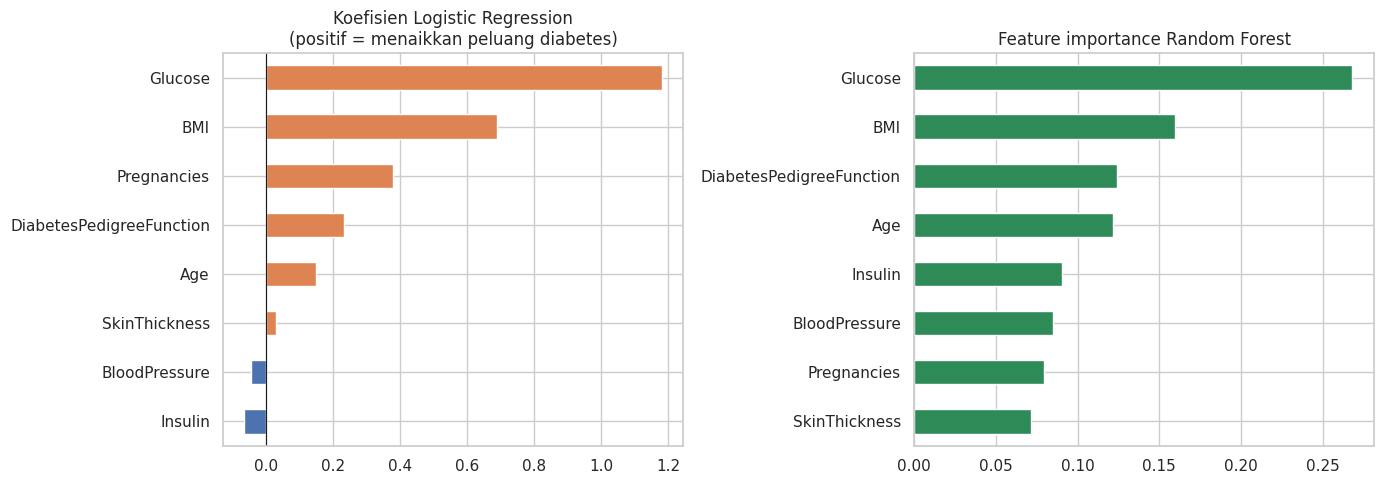

,Koefisien LogReg,Importance RF
Glucose,1.183,0.268
BMI,0.689,0.160
DiabetesPedigreeFunction,0.233,0.124
Age,0.148,0.121
Insulin,-0.066,0.091
BloodPressure,-0.044,0.085
Pregnancies,0.377,0.079
SkinThickness,0.028,0.072


In [ ]:
lr = buat_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)).fit(X_train, y_train)
rf = buat_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)).fit(X_train, y_train)

koef = pd.Series(lr.named_steps["model"].coef_[0], index=FITUR).sort_values()
penting = pd.Series(rf.named_steps["model"].feature_importances_, index=FITUR).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
koef.plot(kind="barh", ax=axes[0], color=["#DD8452" if v > 0 else "#4C72B0" for v in koef])
axes[0].set_title("Koefisien Logistic Regression\n(positif = menaikkan peluang diabetes)")
axes[0].axvline(0, color="k", lw=0.8)
penting.plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Feature importance Random Forest")
plt.tight_layout()
plt.show()

pd.DataFrame({"Koefisien LogReg": koef, "Importance RF": penting}).sort_values("Importance RF", ascending=False).round(3)

### Interpretasi biologis

Berdasarkan hasil Logistic Regression dan Random Forest, Glucose merupakan fitur paling berpengaruh terhadap prediksi diabetes, diikuti BMI. Tingginya glukosa berkaitan dengan gangguan regulasi gula darah akibat resistensi insulin atau gangguan fungsi sel beta pankreas, sedangkan BMI yang tinggi dapat berhubungan dengan peningkatan resistensi insulin. Kedua hasil tersebut sesuai dengan mekanisme biologis diabetes tipe 2. Age, Pregnancies, dan DiabetesPedigreeFunction juga menunjukkan pengaruh positif, yang dapat berkaitan dengan perubahan metabolisme seiring bertambahnya usia, riwayat kehamilan, serta faktor keturunan atau riwayat diabetes keluarga. Namun, pengaruh Pregnancies dapat tumpang tindih dengan Age karena jumlah kehamilan cenderung berkaitan dengan usia. Hasil yang menarik ditemukan pada Insulin dan BloodPressure, yang memiliki koefisien negatif kecil pada Logistic Regression meskipun secara biologis keduanya berkaitan dengan kondisi metabolik. Hal ini kemungkinan dipengaruhi oleh hubungan antarfitur dan keterbatasan data, terutama banyaknya nilai Insulin yang kosong dan diisi menggunakan median. SkinThickness memiliki kontribusi paling rendah pada Random Forest, kemungkinan karena pengukuran ketebalan kulit tidak secara langsung menggambarkan kondisi metabolik dan sebagian datanya juga kosong. Secara keseluruhan, hasil model cukup sesuai dengan teori biologis, terutama pada Glucose dan BMI, tetapi nilai koefisien model tidak dapat langsung diartikan sebagai hubungan sebab-akibat.

## 8. PCA (Principal Component Analysis)

**Apa yang dilakukan?** Data punya 8 fitur, tidak bisa digambar langsung. PCA merangkum 8 fitur menjadi 2 sumbu baru (PC1 dan PC2) yang menyimpan informasi sebanyak mungkin, sehingga data bisa digambar di bidang 2 dimensi. **Label diabetes tidak dipakai** di tahap ini. Kita hanya melihat apakah ada pola alami.

Seluruh 768 baris dipakai karena tahap ini tidak memprediksi data baru.

In [ ]:
# Isi data kosong + samakan skala (tanpa label)
praproses = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
Xs = praproses.fit_transform(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(Xs)

print("Varians yang dijelaskan PC1:", round(pca.explained_variance_ratio_[0] * 100, 1), "%")
print("Varians yang dijelaskan PC2:", round(pca.explained_variance_ratio_[1] * 100, 1), "%")
print("Total PC1 + PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

# kontribusi tiap fitur pada PC1 dan PC2
pd.DataFrame(pca.components_.T, index=FITUR, columns=["PC1", "PC2"]).round(3)

Varians yang dijelaskan PC1: 28.5 %
Varians yang dijelaskan PC2: 18.7 %
Total PC1 + PC2: 47.2 %


,PC1,PC2
Pregnancies,0.301,0.558
Glucose,0.424,-0.082
BloodPressure,0.377,0.172
SkinThickness,0.397,-0.309
Insulin,0.307,-0.236
BMI,0.402,-0.398
DiabetesPedigreeFunction,0.157,-0.273
Age,0.386,0.518


## 9. K-Means (mengelompokkan pasien tanpa label)

**Apa yang dilakukan?** K-Means membagi pasien menjadi K kelompok berdasarkan kemiripan fitur. Jumlah kelompok K harus ditentukan, dibantu dua grafik:
- **Elbow:** cari titik "tekuk siku" di mana penurunan inertia mulai melandai.
- **Silhouette:** makin tinggi makin rapi pemisahan kelompoknya.

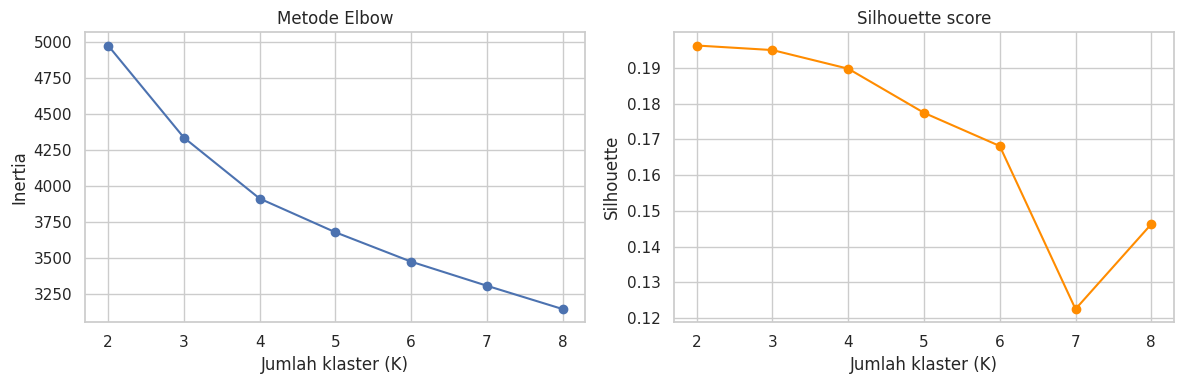

{2: np.float64(0.196), 3: np.float64(0.195), 4: np.float64(0.19), 5: np.float64(0.177), 6: np.float64(0.168), 7: np.float64(0.123), 8: np.float64(0.146)}


In [ ]:
rentang_k = range(2, 9)
inertia, sil = [], []
for k in rentang_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(rentang_k), inertia, "o-")
axes[0].set_title("Metode Elbow")
axes[0].set_xlabel("Jumlah klaster (K)"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(rentang_k), sil, "o-", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Jumlah klaster (K)"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

print({k: round(s, 3) for k, s in zip(rentang_k, sil)})

**Pilih K** berdasarkan dua grafik di atas, lalu ubah angka `K` di sel berikutnya. Nilai awal 2 hanya contoh. Tulis alasan pilihan kalian di sel interpretasi di bawahnya.

In [ ]:
K = 2   # <-- GANTI sesuai hasil grafik elbow dan silhouette di atas

km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xs)
label_klaster = km.labels_

print("K =", K)
print("Silhouette score:", round(silhouette_score(Xs, label_klaster), 3))
print("ARI (Adjusted Rand Index) terhadap status diabetes asli:", round(adjusted_rand_score(y, label_klaster), 3))
print("(ARI mendekati 0 = klaster tidak mirip label, mendekati 1 = sangat mirip)\n")

# Komposisi tiap klaster terhadap status diabetes
komposisi = pd.crosstab(pd.Series(label_klaster, name="Klaster"),
                        y.map({0: "Tidak diabetes", 1: "Diabetes"}).rename("Status asli"))
komposisi["Jumlah"] = komposisi.sum(axis=1)
print(komposisi)

# Ciri rata-rata tiap klaster
profil = X.copy()
profil["Klaster"] = label_klaster
print("\nRata-rata fitur per klaster:")
profil.groupby("Klaster").mean().round(1)

K = 2
Silhouette score: 0.196
ARI (Adjusted Rand Index) terhadap status diabetes asli: 0.161
(ARI mendekati 0 = klaster tidak mirip label, mendekati 1 = sangat mirip)

Status asli  Diabetes  Tidak diabetes  Jumlah
Klaster                                      
0                 195             156     351
1                  73             344     417

Rata-rata fitur per klaster:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Klaster,,,,,,,,
0,5.8,138.0,79.0,34.7,221.0,35.4,0.5,41.1
1,2.2,107.9,66.6,25.1,111.3,30.0,0.4,26.6


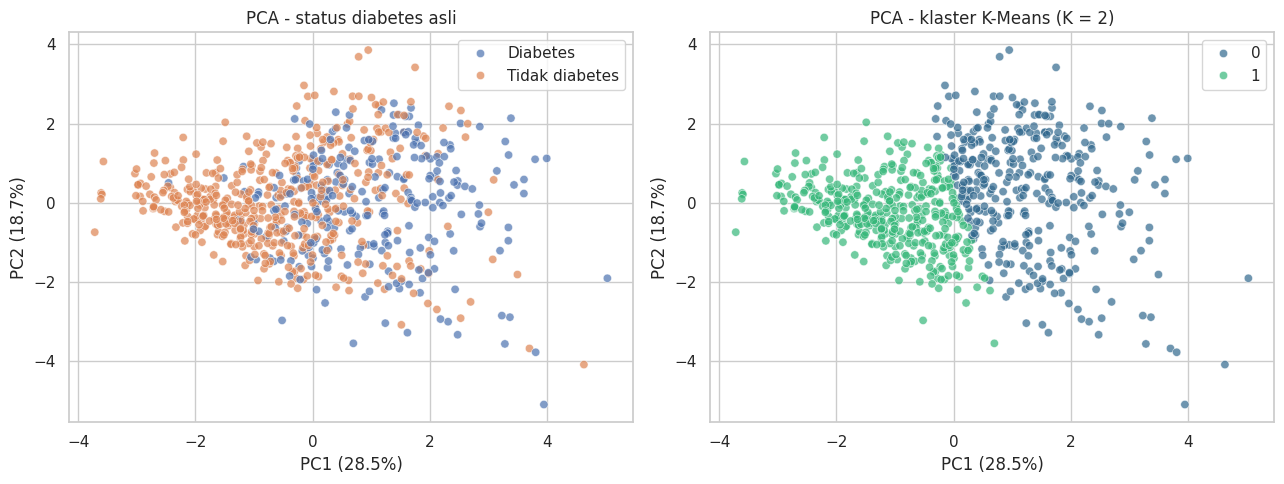

In [ ]:
# Gambar PCA: kiri = warna sesuai status diabetes asli, kanan = warna sesuai klaster K-Means
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(x=Xp[:, 0], y=Xp[:, 1], hue=y.map({0: "Tidak diabetes", 1: "Diabetes"}).values,
                palette=["#4C72B0", "#DD8452"], alpha=0.7, ax=axes[0])
axes[0].set_title("PCA - status diabetes asli")

sns.scatterplot(x=Xp[:, 0], y=Xp[:, 1], hue=label_klaster, palette="viridis", alpha=0.7, ax=axes[1])
axes[1].set_title(f"PCA - klaster K-Means (K = {K})")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout()
plt.show()

### Interpretasi
Berdasarkan grafik Elbow dan Silhouette, jumlah klaster yang dipilih adalah K = 2 karena memiliki nilai Silhouette tertinggi sebesar 0,196 dan menghasilkan pembagian kelompok yang lebih sederhana. Meskipun demikian, nilai tersebut menunjukkan pemisahan antar klaster yang masih lemah. Hasil K-Means menunjukkan kesesuaian yang rendah dengan status diabetes asli, ditunjukkan oleh ARI sebesar 0,161. Klaster 0 terdiri dari 351 pasien dengan proporsi diabetes lebih tinggi, yaitu 55,6%, sedangkan Klaster 1 terdiri dari 417 pasien yang didominasi individu tidak diabetes sebesar 82,5%. Klaster 0 memiliki rata-rata Glucose, BMI, dan Age lebih tinggi dibandingkan Klaster 1, sehingga menunjukkan karakteristik klinis yang relatif lebih berisiko terhadap diabetes. Hal ini sesuai dengan hubungan biologis antara peningkatan glukosa darah, kelebihan berat badan, usia, dan gangguan metabolisme glukosa. Namun, K-Means tidak menggunakan label diabetes dalam proses pengelompokan, sehingga hasil klaster tidak sepenuhnya sesuai dengan status diabetes asli. Pada analisis PCA, PC1 menjelaskan 28,5% variasi dan PC2 menjelaskan 18,7%, dengan total 47,2% variasi data. Visualisasi dua dimensi memperlihatkan pola kelompok, tetapi belum mampu mewakili seluruh informasi dari delapan fitur klinis. Dengan demikian, PCA dan K-Means dapat membantu menemukan pola karakteristik pasien, tetapi hasilnya perlu ditafsirkan secara hati-hati dan tidak digunakan sebagai penentu diagnosis diabetes.

---
## 10. Kesimpulan dan keterbatasan

### Kesimpulan

Data yang digunakan terdiri atas 768 data perempuan suku Pima dengan delapan fitur klinis dan satu target status diabetes. Data memiliki beberapa nilai 0 yang tidak sesuai secara biologis pada fitur Glucose, BloodPressure, SkinThickness, Insulin, dan BMI, sehingga diperlakukan sebagai data kosong dan diisi menggunakan median pada proses preprocessing. Berdasarkan perbandingan model, Logistic Regression menunjukkan kinerja terbaik dengan ROC-AUC validasi silang sebesar 0,843 dan F1 sebesar 0,655, kemudian setelah tuning diperoleh ROC-AUC 0,844. Pada evaluasi data uji, model menghasilkan akurasi 0,688 dan ROC-AUC 0,810, tetapi masih melewatkan 28 dari 54 pasien diabetes. Glucose merupakan fitur paling berpengaruh, diikuti BMI, berdasarkan koefisien Logistic Regression dan feature importance Random Forest. Analisis PCA menunjukkan bahwa PC1 dan PC2 mampu menjelaskan 47,2% variasi data, sedangkan K-Means dengan K = 2 membentuk kelompok dengan karakteristik klinis yang berbeda, tetapi pemisahannya masih lemah berdasarkan nilai Silhouette 0,196 dan ARI 0,161. Secara keseluruhan, Logistic Regression mampu memprediksi status diabetes dengan cukup baik dibandingkan baseline, tetapi hasil pengelompokan tanpa label belum mampu merepresentasikan status diabetes secara kuat.

### Keterbatasan

Penelitian ini memiliki beberapa keterbatasan, yaitu jumlah data yang relatif terbatas, hanya mencakup perempuan suku Pima sehingga hasilnya belum tentu dapat digeneralisasikan ke populasi lain, serta adanya nilai data yang tidak valid secara biologis dan perlu diisi menggunakan median. Model juga belum diuji menggunakan dataset eksternal sehingga kemampuan generalisasinya belum dapat dipastikan. Selain itu, recall diabetes pada data uji masih sebesar 0,481, sehingga model belum mampu mendeteksi seluruh pasien diabetes dengan baik dan masih berisiko melewatkan kasus diabetes. Hasil analisis machine learning hanya menunjukkan pola dan hubungan statistik antarvariabel, bukan hubungan sebab-akibat, sehingga model ini belum dapat digunakan sebagai pengganti diagnosis medis.

## Daftar pustaka dan sumber data
- Sumber data: Pima Indians Diabetes Database (OpenML / Kaggle / UCI Machine Learning Repository), [tuliskan tautan yang dipakai]
- Smith, J. W., dkk. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. *Proceedings of the Annual Symposium on Computer Application in Medical Care*, 261-265.
- Pedregosa, F., dkk. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.